# Our PCA/SVM feature study — understand it, run it, explain it
**Qiskit Fall Fest EMSI · Crop classification · Second research notebook**

This follows the **same seven sections, 25-cell layout and four figure slots**
as `QFF_Quantum_Crop_Research.ipynb`. It documents the next completed investigation:
**does PCA discard small but useful crop clues?** We compare four, six and eight
components with the existing classical RBF SVM. Six components improved mean
precision across all three crops in **training-only cross-validation**.

This was a **classical feature-representation experiment**, not a new quantum
architecture or hybrid classifier. The ring circuit appears only as the unchanged
reference, so we can connect the findings to our quantum project honestly.

**Start:** choose the project's **Crop challenge / `.venv` Python 3.12** kernel,
leave `RUN_MODE='saved'`, then **Restart Kernel → Run All**. The default loads
and rescores verified CV predictions. It also fits the predefined six/eight-PC
pipelines on training only for the real-field explorer, because those full-training
checkpoints were not saved previously. New fits and demonstrations are labeled.

In [1]:
from pathlib import Path
import sys, json, hashlib, subprocess, uuid
from datetime import datetime, timezone
from importlib.metadata import version
from time import perf_counter

ROOT=next((p for p in [Path.cwd(),*Path.cwd().parents]
           if (p/'challenge/data.py').is_file() and (p/'data/manifest.json').is_file()),None)
if ROOT is None:raise RuntimeError('Open the project folder or notebooks/ and restart the kernel.')
if sys.version_info[:2]!=(3,12) or Path(sys.prefix).resolve()!=(ROOT/'.venv').resolve():
    raise RuntimeError(f'Select the project .venv / Crop challenge kernel. Current Python: {sys.executable}')
sys.path.insert(0,str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display, Markdown
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import StratifiedKFold, GridSearchCV, train_test_split
from sklearn.metrics import make_scorer, f1_score
from challenge.data import load_data
from challenge.metrics import score
from experiments.feature_representation.models import model, representation
from experiments.entanglement_topology.model import TopologyClassifier

get_ipython().run_line_magic('matplotlib','inline')
plt.rcParams.update({'font.size':10,'figure.dpi':120,'axes.spines.top':False,'axes.spines.right':False})
LABELS=['alfalfa','maize','wheat']
CROP_COLORS=['#23865d','#c98919','#596fb0']
VIEWS=['pca4','pca6','pca8']
VIEW_COLORS={'pca4':'#23779d','pca6':'#c38a2c','pca8':'#32825a'}
ARCHIVE=ROOT/'outputs/feature_representation_2026-11-21'
print('Python',sys.version.split()[0],'| scikit-learn',version('scikit-learn'),'| Qiskit',version('qiskit'))

Python 3.12.16 | scikit-learn 1.9.1 | Qiskit 2.4.2


**Choose how much work to run.** This SVM is deterministic: there are no random
quantum starting angles. Repeats **0,1,2** change the stratified data partitions,
using split seeds **2026,2027,2028**. Their variation is not initialization noise
or a confidence interval; the repeats reuse the same fields.

| Mode | Main comparison | Fields evaluated | Typical local cost |
|---|---|---|---|
| `saved` | Load and verify the completed nested-CV records | 914 training fields, out of fold per repeat | A few seconds |
| `quick` | Fit 4/6/8-PC pipelines on 120 training fields, with training-only tuning | 180 disjoint training fields per repeat | A few seconds |
| `full` | Reproduce the original nested CV: three outer folds, three inner folds, nine settings | 914 training fields, out of fold per repeat | Usually seconds to tens of seconds |

All modes prepare the same predefined full-training models for the single-field
explorer. The archived four-PC checkpoint is loaded; six/eight-PC demo checkpoints
are freshly fitted using the training-only grid. Quick results are teaching
results, not replacements for the completed study. No validation score selects a model.

In [2]:
RUN_MODE = 'saved'               # 'saved', 'quick', or 'full'
CV_REPEATS = [0, 1, 2]           # Use [0] for a shorter reproduction.
MATRIX_REPEAT = 0                # A fixed illustrative repeat, not the highest-scoring repeat.

if RUN_MODE not in {'saved','quick','full'}:raise ValueError('Choose saved, quick or full.')
if not CV_REPEATS or len(set(CV_REPEATS))!=len(CV_REPEATS) or any(r not in [0,1,2] for r in CV_REPEATS):
    raise ValueError('Choose distinct repeat indices from 0, 1 and 2.')
if MATRIX_REPEAT not in CV_REPEATS:raise ValueError('MATRIX_REPEAT must be in CV_REPEATS.')

In [3]:
def digest(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

branch=subprocess.check_output(['git','branch','--show-current'],cwd=ROOT,text=True).strip()
if branch!='research/quantum-model-optimization':
    raise RuntimeError('Use research/quantum-model-optimization, preserving pending changes.')
pinned=json.loads((ROOT/'experiments/pca_svm_notebook/artifact_manifest.json').read_text())['sha256']
for relative,expected in pinned.items():
    path=ROOT/relative
    if not path.is_file():raise FileNotFoundError(f'Required verified file is missing: {path}')
    if digest(path)!=expected:raise ValueError(f'Verified file changed: {relative}')

tracked=subprocess.check_output(['git','ls-files','-z'],cwd=ROOT).decode().split('\0')
protected={ROOT/p for p in tracked if p and not p.startswith(('experiments/pca_svm_notebook/','notebooks/QFF_PCA_SVM_Feature_Research.ipynb'))}
for folder in (ROOT/'outputs').iterdir():
    if folder.is_dir() and folder.name not in ['pca_svm_notebook','pca_svm_notebook_verification']:
        protected.update(p for p in folder.rglob('*') if p.is_file() and '__pycache__' not in p.parts)
locked={str(p.relative_to(ROOT)):digest(p) for p in protected if p.is_file()}
tag=datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')+'_'+uuid.uuid4().hex[:8]
OUT=ROOT/'outputs/pca_svm_notebook'/tag
OUT.mkdir(parents=True,exist_ok=False)

def show_figure(fig,name,explanation):
    destination=OUT/(name+'.png')
    if destination.exists():destination=OUT/(name+'_'+uuid.uuid4().hex[:8]+'.png')
    fig.savefig(destination,bbox_inches='tight',dpi=150)
    display(fig);plt.close(fig)
    display(Markdown('*How to read it:* '+explanation))

print('Mode:',RUN_MODE,'| existing PCA/SVM study | New output folder:',OUT)
print('The first research notebook and original project files are protected.')

Mode: saved | existing PCA/SVM study | New output folder: /Users/alibourak/QiskitFallFest2026/QiskitFallFest_EMSI_QuantumAfrica/outputs/pca_svm_notebook/20261121T090342Z_057c1084
The first research notebook and original project files are protected.


## 1 — What we are classifying

As in the ring notebook, each row is one real field with **13 satellite-derived
measurements** and a crop label: alfalfa, maize or wheat. We have **914 training**,
**150 validation**, and **221 unlabeled test** fields. IDs are bookkeeping, never
model inputs. The loader verifies file hashes, schemas and disjoint splits.

NDVI is a vegetation clue, conventionally
\(\mathrm{NDVI}=(\mathrm{NIR}-\mathrm{red})/(\mathrm{NIR}+\mathrm{red})\).
Maize and wheat overlap in NDVI, so their other measurements matter. This study
asks whether compressing those measurements to four PCs removes useful clues.
The published comparison uses **training data only**, not the released validation set.

In [4]:
tables,prepared_release,manifest,_=load_data()
train=tables['train'].copy()
validation=tables['validation'].copy()
features=manifest['features']
assert manifest['labels']==LABELS and len(features)==13
assert len(train)==914 and len(validation)==150
display(pd.DataFrame({'training fields':train.target.value_counts().reindex(LABELS),
                      'validation fields':validation.target.value_counts().reindex(LABELS),
                      'training median NDVI':train.groupby('target').NDVI.median().reindex(LABELS)}))
print('Features:',', '.join(features))
print('Published metrics below use only out-of-fold training predictions. No test inference.')

,training fields,validation fields,training median NDVI
target,,,
alfalfa,247,50,0.673304
maize,242,50,0.280369
wheat,425,50,0.295204


Features: B1, B2, B3, B4, B5, B6, B7, B8, B8A, B9, B11, B12, NDVI
Published metrics below use only out-of-fold training predictions. No test inference.


Wheat is most common in training. Macro-F1 gives each crop equal weight despite
that imbalance. The prepared cohort is from Doukkala around 25 April 2024; band
calibration and cloud processing are not fully documented. See `data/README.md`
for limitations and attribution: Ouassanouan et al.,
[Figshare v2](https://doi.org/10.6084/m9.figshare.28486022.v2), CC BY 4.0.

## 2 — From 13 measurements to four, six or eight components

**Standardization**, \(z=(x-\mu)/\sigma\), expresses a value as distance from
its training mean in training-standard-deviation units. It prevents large band
numbers from dominating NDVI simply through numerical scale.

**PCA** rotates these feature axes into weighted combinations called principal
components, ordered by variation. A PC is not a single original band. Compressing
a picture can preserve most of its appearance while removing a small identifying
mark. Likewise, **low variance does not mean useless for recognizing a crop**.

We preserve the existing recipe: **StandardScaler → PCA(k) → StandardScaler →
RBF SVM**, with \(k=4,6,8\). Only training portions fit the scalers, PCA and SVM.
This classical classifier uses the PC values directly: **there is no angle map
or quantum encoding in the PCA/SVM experiment**.

In [5]:
raw_train=train[features].to_numpy()
raw_validation=validation[features].to_numpy()
all_pca=PCA(svd_solver='full').fit(StandardScaler().fit_transform(raw_train))
display(pd.DataFrame({'retained components':[4,6,8],
                      'training variance retained':[all_pca.explained_variance_ratio_[:k].sum() for k in [4,6,8]]})
        .style.format({'training variance retained':'{:.2%}'}))

# Reuse existing representations. This full-training fit is DESCRIPTIVE only.
# The CV procedure below refits all preprocessing within each training fold.
descriptive_views={v:representation(v).fit_transform(raw_train) for v in VIEWS}
np.testing.assert_allclose(descriptive_views['pca4'],prepared_release['X_train'],atol=1e-10,rtol=0)
print({v:x.shape for v,x in descriptive_views.items()})

,retained components,training variance retained
0,4,99.12%
1,6,99.71%
2,8,99.93%


{'pca4': (914, 4), 'pca6': (914, 6), 'pca8': (914, 8)}


Four PCs retain **99.12%** of variance; six retain **99.71%** and eight **99.93%**.
Yet six improves classical prediction. Variance retention measures reconstruction
of measurements, not crop-classification quality. Standardizing each retained PC
also changes distance geometry; the broader study used fixed-SVM and logistic
controls as well. These classical findings do not establish a quantum improvement.

## 3 — The PCA/SVM pipeline, explained

The **architecture change** is a classical pipeline change: give the same RBF
SVM six or eight standardized PCs instead of four. We reuse the existing
`experiments.feature_representation.models.model` factory.

An **SVM** learns separating boundaries from training fields. Some fields,
called **support vectors**, determine those boundaries. An **RBF kernel** allows
curved boundaries using similarity
\[
K(u,v)=\exp(-\gamma\lVert u-v\rVert^2).
\]
Nearby feature vectors are more similar. **Gamma** controls how local the
influence is; **C** controls the tradeoff between margin width and fitting errors.
We consider exactly the original nine combinations: C=1,10,100 and
gamma=0.01,0.1,`scale`, selected using training-only inner CV.

**Connection to notebook one:** the ring QNN still has four qubits, twelve RY
angles and two CX blocks. It is not widened, trained or used as a head here.
The actual Qiskit circuit below is explicitly the **unchanged quantum reference**,
not a claimed circuit implementing an SVM or six-component quantum encoding.

,pipeline,PC inputs,classifier,training-only settings considered,quantum gates in this classifier
0,pca4,4,existing RBF SVC,9,0
1,pca6,6,existing RBF SVC,9,0
2,pca8,8,existing RBF SVC,9,0


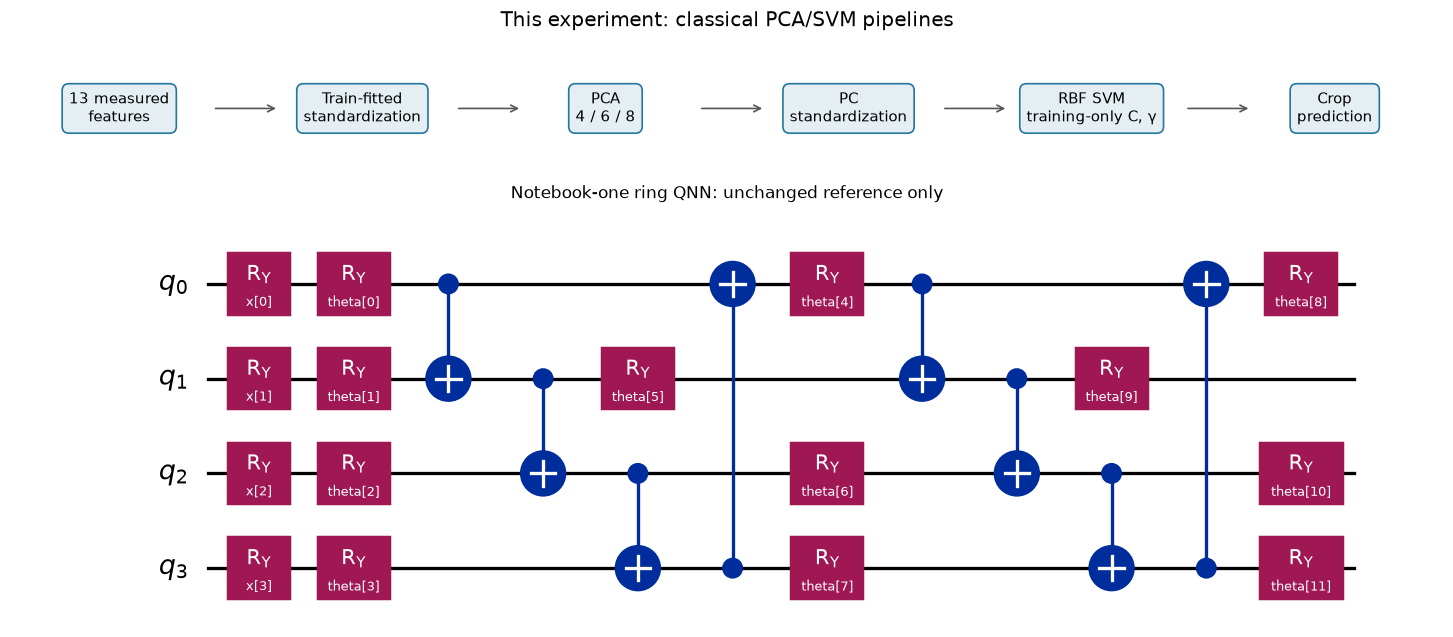

*How to read it:* Top: only the retained PC count changes between the classical recipes; C and gamma are selected through the same training-only rule. Bottom: actual Qiskit ring circuit for context, not part of the SVM. No extra qubits or hybrid quantum/classical head are introduced.

In [6]:
display(pd.DataFrame([{'pipeline':v,'PC inputs':int(v[3:]),'classifier':'existing RBF SVC',
                       'training-only settings considered':9,'quantum gates in this classifier':0} for v in VIEWS]))
quantum_reference=TopologyClassifier(LABELS,topology='ring',max_evals=100)
fig,axes=plt.subplots(2,1,figsize=(12,5.2),gridspec_kw={'height_ratios':[1,3]},layout='constrained')
axes[0].axis('off')
stages=['13 measured\nfeatures','Train-fitted\nstandardization','PCA\n4 / 6 / 8','PC\nstandardization','RBF SVM\ntraining-only C, γ','Crop\nprediction']
for i,label in enumerate(stages):
    x=.075+i*.17
    axes[0].text(x,.48,label,transform=axes[0].transAxes,ha='center',va='center',fontsize=9,
                 bbox={'boxstyle':'round,pad=.45','facecolor':'#e5eef3','edgecolor':'#23779d'})
    if i<5:axes[0].annotate('',xy=(x+.112,.48),xytext=(x+.065,.48),xycoords='axes fraction',arrowprops={'arrowstyle':'->','color':'#555555'})
axes[0].set_title('This experiment: classical PCA/SVM pipelines')
quantum_reference.circuit.draw(output='mpl',ax=axes[1],fold=24)
axes[1].set_title('Notebook-one ring QNN: unchanged reference only',fontsize=10)
show_figure(fig,'01_pipeline_and_quantum_reference','Top: only the retained PC count changes between the classical recipes; C and gamma are selected through the same training-only rule. Bottom: actual Qiskit ring circuit for context, not part of the SVM. No extra qubits or hybrid quantum/classical head are introduced.')

The previous model produced three exact circuit probabilities. The existing SVC
has `probability=False`: it produces a crop prediction and **decision scores**,
not crop probabilities. We keep that configuration unchanged. Support-vector
counts depend on training data, rather than a fixed set of twelve gate angles.
Do not interpret a decision score of 2 as “200% confidence.”

## 4 — Train or restore the PCA/SVM experiment

The SVM solver optimizes its margin/error objective. It does not have the ring
QNN's cross-entropy/parameter-shift loop. **No epoch-loss history was saved**,
so the curve in this section shows the actual **training-only inner-CV tuning
scores**, not an invented loss trajectory.

**Nested cross-validation** keeps the held-out fields out of every decision:

1. Split the 914 training fields into three **outer folds**.
2. Inside each outer training portion, use three **inner folds** to choose C/gamma.
3. Every candidate includes its own fitted scalers and PCA inside those inner folds.
4. Refit the selected pipeline on the outer training portion and predict its hidden fold.
5. Pool the three outer predictions, so every field has one out-of-fold prediction.

Repeat with split seeds 2026,2027,2028. All representations use the same outer
folds. The inner seed is `30000 + 100*repeat + outer_fold`, exactly as archived.
These folds are stratified by crop, not spatial. Repeated research on this same
training cohort is selection evidence, not an untouched generalization estimate.

In [7]:
archive_repeats=json.loads((ARCHIVE/'repeat_runs.json').read_text())
archive_folds=json.loads((ARCHIVE/'fold_runs.json').read_text())
archived={(v,r):next(x for x in archive_repeats if x['learner']=='svm_nested' and x['view']==v and x['repeat']==r)
          for v in VIEWS for r in [0,1,2]}
fold_record={(v,r,f):next(x for x in archive_folds if x['learner']=='svm_nested' and x['view']==v and x['repeat']==r and x['fold']==f)
             for v in VIEWS for r in [0,1,2] for f in [0,1,2]}
scorer=make_scorer(f1_score,labels=LABELS,average='macro',zero_division=0)

def training_grid(view,split_seed):
    # Existing working model; the COMPLETE preprocessing pipeline stays inside CV.
    return GridSearchCV(model(view,'svm_nested'),
        {'classifier__C':[1,10,100],'classifier__gamma':[.01,.1,'scale']},
        scoring=scorer,cv=StratifiedKFold(3,shuffle=True,random_state=split_seed),
        n_jobs=1,refit=True,error_score='raise')

def grid_curve(search):
    return [{'parameters':p,'mean_f1':float(s)} for p,s in zip(search.cv_results_['params'],search.cv_results_['mean_test_score'])]

saved_oof={}
for v in VIEWS:
    for r in CV_REPEATS:
        p=pd.read_csv(ARCHIVE/f'svm_nested_{v}_repeat_{r}_oof.csv')
        np.testing.assert_array_equal(p.sample_id,train.sample_id)
        np.testing.assert_array_equal(p.target,train.target)
        assert score(train.target,p.prediction,LABELS)==archived[v,r]['metrics']
        saved_oof[v,r]=p
scope=('FRESH quick teaching holdout: 120 fit / 180 held-out TRAINING fields' if RUN_MODE=='quick'
       else ('LOADED verified training-only nested CV; predictions freshly rescored' if RUN_MODE=='saved'
             else 'FRESH reproduction of training-only nested CV'))
print(scope,'| repeat indices:',CV_REPEATS)

LOADED verified training-only nested CV; predictions freshly rescored | repeat indices: [0, 1, 2]


In [8]:
run_rows,metrics_by_run,predictions,tuning_curves={},{},{},{}
records=[];reproduction_checks=[]
for repeat in CV_REPEATS:
    split_seed=2026+repeat
    if RUN_MODE=='quick':
        pool,held=train_test_split(np.arange(len(train)),test_size=180,stratify=train.target,random_state=split_seed)
        fit,_=train_test_split(pool,train_size=120,stratify=train.target.iloc[pool],random_state=split_seed)
        splits=[(fit,held)];eval_indices=held
    else:
        splits=list(StratifiedKFold(3,shuffle=True,random_state=split_seed).split(raw_train,train.target))
        eval_indices=np.arange(len(train))
    for view in VIEWS:
        if RUN_MODE=='saved':
            prediction=saved_oof[view,repeat].prediction.to_numpy()
            fit_seconds=archived[view,repeat]['fit_and_search_seconds']
            origin='LOADED prior verified CV results; historical fit/search time'
            tuning_curves[view,repeat]=fold_record[view,repeat,0]['inner_grid_scores']
        else:
            oof=np.empty(len(train),dtype=object);fit_seconds=0.
            for fold,(fit,held) in enumerate(splits):
                assert not set(fit)&set(held)
                search=training_grid(view,30000+100*repeat+fold)
                start=perf_counter();search.fit(raw_train[fit],train.target.to_numpy()[fit]);fit_seconds+=perf_counter()-start
                oof[held]=search.predict(raw_train[held])
                curve=grid_curve(search)
                if fold==0:tuning_curves[view,repeat]=curve
                if RUN_MODE=='full':
                    old=fold_record[view,repeat,fold]
                    assert search.best_params_==old['best_parameters']
                    assert [x['parameters'] for x in curve]==[x['parameters'] for x in old['inner_grid_scores']]
                    np.testing.assert_allclose([x['mean_f1'] for x in curve],[x['mean_f1'] for x in old['inner_grid_scores']],atol=1e-12,rtol=0)
                    np.testing.assert_array_equal(oof[held],saved_oof[view,repeat].prediction.to_numpy()[held])
                    reproduction_checks.append({'view':view,'repeat':repeat,'fold':fold,'inner_scores_parameters_outer_predictions_match':True})
                records.append({'view':view,'repeat':repeat,'fold':fold,'split_seed':split_seed,
                                'fit_fields':len(fit),'held_out_fields':len(held),'best_parameters':search.best_params_,
                                'inner_grid_scores':curve})
            prediction=oof[eval_indices]
            origin='FRESH fit and training-only tuning executed in this notebook'
        truth=train.target.to_numpy()[eval_indices]
        metrics=score(truth,prediction,LABELS)
        if RUN_MODE!='quick':assert metrics==archived[view,repeat]['metrics']
        metrics_by_run[view,repeat]=metrics;predictions[view,repeat]=prediction
        row={'view':view,'repeat':repeat,'split_seed':split_seed,'evaluation_fields':len(truth),
             'accuracy':metrics['accuracy'],'macro_f1':metrics['macro_f1'],'fit_search_seconds':fit_seconds,
             'scope':scope,'origin':origin}
        for j,crop in enumerate(LABELS):
            for key in ['precision','recall']:row[f'{key}_{crop}']=metrics[key][j]
        run_rows[view,repeat]=row
        pd.DataFrame({'sample_id':train.sample_id.iloc[eval_indices],'target':truth,'prediction':prediction}).to_csv(OUT/f'{view}_repeat_{repeat}_predictions.csv',index=False)
        print(f'{view}, repeat {repeat}, split seed {split_seed}: F1={metrics["macro_f1"]:.4f} | {origin}',flush=True)
results=pd.DataFrame(run_rows.values())
results.to_csv(OUT/'svm_metrics_per_repeat.csv',index=False)
(OUT/'fresh_fold_records.json').write_text(json.dumps(records,indent=2))
display(results[['view','repeat','split_seed','accuracy','macro_f1','fit_search_seconds','origin']])

# Real-field explorer: no archived 6/8-PC full-training checkpoint existed.
# Fit the PREDEFINED grid on TRAINING only; do not score or select on validation.
demo_models={'pca4':joblib.load(ARCHIVE/'full_training_pca4_svm.joblib')}
demo_provenance={'pca4':'LOADED verified full-training pipeline'}
for view in ['pca6','pca8']:
    search=training_grid(view,2026).fit(raw_train,train.target.to_numpy())
    demo_models[view]=search.best_estimator_
    demo_provenance[view]='FRESH full-training pipeline; training-only CV selected settings; no validation ranking'
    joblib.dump(demo_models[view],OUT/f'demo_{view}_training_only_pipeline.joblib')
demo_config=[{'view':v,'origin':demo_provenance[v],
              'C':demo_models[v].named_steps['classifier'].C,
              'gamma':demo_models[v].named_steps['classifier'].gamma,
              'support_vectors':int(demo_models[v].named_steps['classifier'].n_support_.sum())} for v in VIEWS]
(OUT/'demo_training_configurations.json').write_text(json.dumps(demo_config,indent=2))
display(pd.DataFrame(demo_config))

pca4, repeat 0, split seed 2026: F1=0.8961 | LOADED prior verified CV results; historical fit/search time


pca6, repeat 0, split seed 2026: F1=0.9062 | LOADED prior verified CV results; historical fit/search time


pca8, repeat 0, split seed 2026: F1=0.9058 | LOADED prior verified CV results; historical fit/search time


pca4, repeat 1, split seed 2027: F1=0.8909 | LOADED prior verified CV results; historical fit/search time


pca6, repeat 1, split seed 2027: F1=0.9098 | LOADED prior verified CV results; historical fit/search time


pca8, repeat 1, split seed 2027: F1=0.9126 | LOADED prior verified CV results; historical fit/search time


pca4, repeat 2, split seed 2028: F1=0.8947 | LOADED prior verified CV results; historical fit/search time


pca6, repeat 2, split seed 2028: F1=0.9125 | LOADED prior verified CV results; historical fit/search time


pca8, repeat 2, split seed 2028: F1=0.9133 | LOADED prior verified CV results; historical fit/search time


,view,repeat,split_seed,accuracy,macro_f1,fit_search_seconds,origin
0,pca4,0,2026,0.896061,0.896123,0.291720,LOADED prior verified CV results; historical f...
1,pca6,0,2026,0.907002,0.906216,0.320623,LOADED prior verified CV results; historical f...
2,pca8,0,2026,0.905908,0.905781,0.314398,LOADED prior verified CV results; historical f...
3,pca4,1,2027,0.890591,0.890888,0.293626,LOADED prior verified CV results; historical f...
4,pca6,1,2027,0.909190,0.909788,0.314535,LOADED prior verified CV results; historical f...
5,pca8,1,2027,0.912473,0.912619,0.337202,LOADED prior verified CV results; historical f...
6,pca4,2,2028,0.894967,0.894724,0.294722,LOADED prior verified CV results; historical f...
7,pca6,2,2028,0.912473,0.912483,0.303857,LOADED prior verified CV results; historical f...
8,pca8,2,2028,0.913567,0.913276,0.317610,LOADED prior verified CV results; historical f...


,view,origin,C,gamma,support_vectors
0,pca4,LOADED verified full-training pipeline,10,0.1,228
1,pca6,FRESH full-training pipeline; training-only CV...,10,0.1,209
2,pca8,FRESH full-training pipeline; training-only CV...,10,scale,241


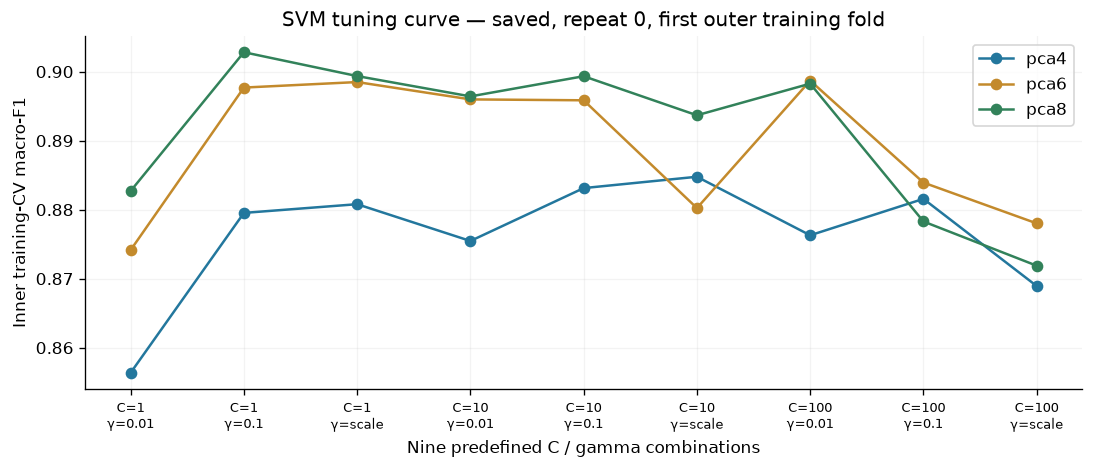

*How to read it:* Higher is better on inner training-CV folds. Adjacent points are different C/gamma settings, not epochs or accepted optimizer steps. This is the actual saved or freshly reproduced grid search, not a quantum loss curve. The outer hidden fold does not choose a setting. Quick mode shows its smaller training-only grid.

In [9]:
fig,ax=plt.subplots(figsize=(9,3.8),layout='constrained')
for view in VIEWS:
    curve=tuning_curves[view,MATRIX_REPEAT]
    ax.plot(range(1,10),[x['mean_f1'] for x in curve],marker='o',label=view,color=VIEW_COLORS[view])
labels=[f"C={x['parameters']['classifier__C']}\nγ={x['parameters']['classifier__gamma']}" for x in curve]
ax.set(xticks=range(1,10),xticklabels=labels,xlabel='Nine predefined C / gamma combinations',
       ylabel='Inner training-CV macro-F1',title=f'SVM tuning curve — {RUN_MODE}, repeat {MATRIX_REPEAT}, first outer training fold')
ax.tick_params(axis='x',labelsize=8);ax.legend();ax.grid(alpha=.15)
show_figure(fig,'02_training_cv_tuning_curve','Higher is better on inner training-CV folds. Adjacent points are different C/gamma settings, not epochs or accepted optimizer steps. This is the actual saved or freshly reproduced grid search, not a quantum loss curve. The outer hidden fold does not choose a setting. Quick mode shows its smaller training-only grid.')

## 5 — Evaluate: which crop mistakes remain?

**Precision** asks “of the fields we call maize, how many really are maize?”
**Recall** asks “of all real maize fields, how many did we find?” **Accuracy**
counts correct predictions across fields; **macro-F1** gives each crop's
precision/recall balance equal weight:
\[
P=\frac{TP}{TP+FP},\qquad R=\frac{TP}{TP+FN},\qquad F1=\frac{2PR}{P+R}.
\]
For example, 90 correct maize predictions out of 100 maize predictions means
90% precision. This is an illustrative count, not a measured result below.

The key six-PC result is improved **mean precision across all crops**. We show
each repeat too: wheat precision dipped slightly in repeat 1. A mean improvement
does not imply every crop improved in every repeat, or guarantee new-region accuracy.

,accuracy,macro_f1,macro_f1_repeat_SD,fit_search_seconds
view,,,,
pca4,0.893873,0.893912,0.002213,0.293356
pca6,0.909555,0.909496,0.002567,0.313005
pca8,0.910649,0.910559,0.003389,0.323070


,precision_alfalfa,precision_maize,precision_wheat,recall_alfalfa,recall_maize,recall_wheat
view,,,,,,
pca4,90.27%,86.13%,90.84%,92.58%,88.84%,87.84%
pca6,91.37%,89.70%,91.44%,92.85%,89.94%,90.43%
pca8,91.86%,89.60%,91.47%,92.85%,89.94%,90.67%


,crop,4-PC mean precision,6-PC mean precision,precision gain (percentage points)
0,alfalfa,0.902680,0.913678,1.099792
1,maize,0.861258,0.896969,3.571079
2,wheat,0.908425,0.914382,0.595681


,repeat,precision gain pp: alfalfa,precision gain pp: maize,precision gain pp: wheat
0,0,0.644841,3.260981,0.040169
1,1,1.746875,5.065895,-0.124660
2,2,0.907660,2.386360,1.871534


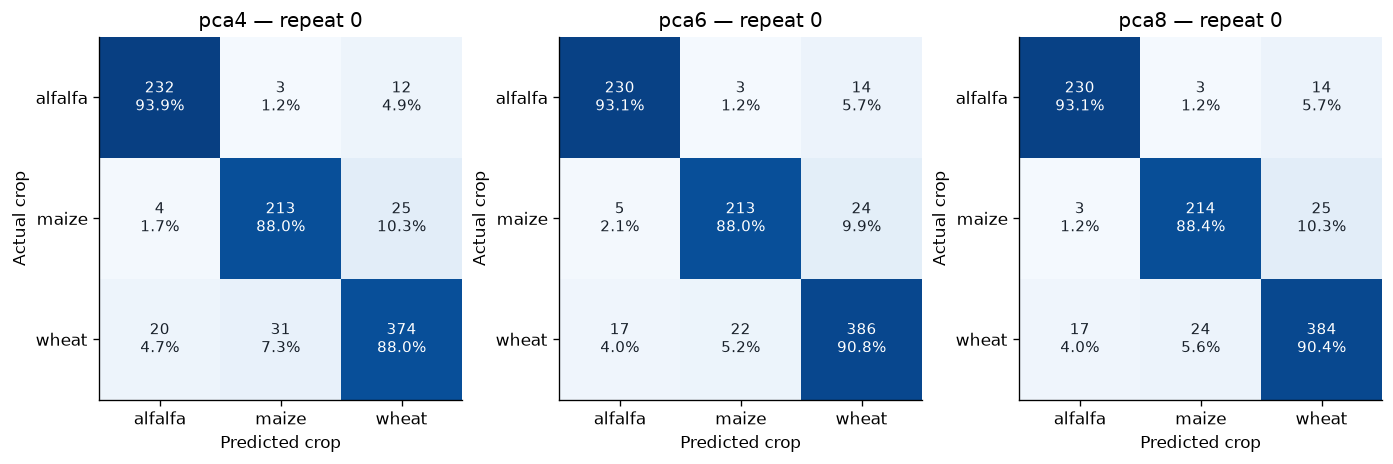

*How to read it:* All panels use the same hidden training fields and repeat. Rows are actual crops; columns predictions. Read a row to understand recall; read a column to understand precision. These are OOF results over 914 training fields in saved/full mode; quick uses 180 held-out training fields. None is the released-validation confusion matrix.

In [10]:
numeric=['accuracy','macro_f1','fit_search_seconds',*[f'{k}_{c}' for k in ['precision','recall'] for c in LABELS]]
means=results.groupby('view')[numeric].mean().reindex(VIEWS)
means['macro_f1_repeat_SD']=results.groupby('view').macro_f1.std(ddof=0).reindex(VIEWS)
display(means[['accuracy','macro_f1','macro_f1_repeat_SD','fit_search_seconds']])
crop_columns=[f'{k}_{c}' for k in ['precision','recall'] for c in LABELS]
display(means[crop_columns].style.format('{:.2%}'))
delta=pd.DataFrame({'crop':LABELS,
    '4-PC mean precision':[means.loc['pca4',f'precision_{c}'] for c in LABELS],
    '6-PC mean precision':[means.loc['pca6',f'precision_{c}'] for c in LABELS]})
delta['precision gain (percentage points)']=100*(delta['6-PC mean precision']-delta['4-PC mean precision'])
display(delta)
repeat_changes=[]
for repeat in CV_REPEATS:
    a=metrics_by_run['pca4',repeat];b=metrics_by_run['pca6',repeat]
    repeat_changes.append({'repeat':repeat,**{f'precision gain pp: {c}':100*(b['precision'][j]-a['precision'][j]) for j,c in enumerate(LABELS)}})
display(pd.DataFrame(repeat_changes))
means.to_csv(OUT/'svm_mean_metrics.csv')
delta.to_csv(OUT/'precision_improvements.csv',index=False)
fig,axes=plt.subplots(1,3,figsize=(11.5,3.9),layout='constrained')
for ax,view in zip(axes,VIEWS):
    cm=np.asarray(metrics_by_run[view,MATRIX_REPEAT]['confusion']);fractions=cm/cm.sum(axis=1,keepdims=True)
    ax.imshow(fractions,vmin=0,vmax=1,cmap='Blues')
    for i in range(3):
        for j in range(3):ax.text(j,i,f'{cm[i,j]}\n{fractions[i,j]:.1%}',ha='center',va='center',fontsize=9,color='white' if fractions[i,j]>.55 else '#18202a')
    ax.set(xticks=range(3),yticks=range(3),xticklabels=LABELS,yticklabels=LABELS,
           xlabel='Predicted crop',ylabel='Actual crop',title=f'{view} — repeat {MATRIX_REPEAT}')
show_figure(fig,'03_training_only_confusion_matrices','All panels use the same hidden training fields and repeat. Rows are actual crops; columns predictions. Read a row to understand recall; read a column to understand precision. These are OOF results over 914 training fields in saved/full mode; quick uses 180 held-out training fields. None is the released-validation confusion matrix.')

In the completed study, **four → six PCs** raised mean precision:
alfalfa **90.27% → 91.37%**, maize **86.13% → 89.70%**, wheat **90.84% → 91.44%**.
Macro-F1 rose **0.8939 → 0.9095**; wheat recall rose **87.84% → 90.43%**.
Eight PCs reached **0.9106** macro-F1, a much smaller additional mean gain.

Across three OOF passes of the same fields, mistaken maize predictions fell
**104 → 75** with six PCs, while correct maize predictions rose **645 → 653**.
These are repeated decisions, not different physical fields. Six PCs repaired
102 earlier wrong decisions but introduced 59 new ones; improvements have tradeoffs.
Repeat 1's wheat precision changed **91.315% → 91.190%**, even though the overall
mean increased. Quick-mode findings must be read from their own tables.

The original study's overall best classical representation was standardized
raw13 (mean F1 0.9130), not six PCs. Here six is the primary **information-retention
comparison**, not a claim to the best possible classical or quantum model.
No aggregate released-validation scores existed for these feature candidates;
this notebook does not invent them or rank pipelines on validation.

## 6 — Predict one real validation field

Change **FIELD_INDEX** (0–149) and **DEMO_VIEW** (`pca4`, `pca6`, `pca8`), then
rerun the next cell. As in notebook one, it shows a real field's 13 measurements,
prepared values, prediction and correct/incorrect status. Here there are no
encoded angles or circuit probabilities: the SVM consumes the PCs directly.

The four-PC pipeline is loaded from the archive; six/eight-PC pipelines were
freshly fitted on all 914 training fields using the predefined training-only
grid. This is a **new individual-field demonstration**, not an archived validation
result or evidence of improved validation precision. No settings are changed
in response to the selected field or its label.

**Actual validation field `r2_4769de2441c6188e` · true crop: wheat**

,feature,actual measurement
0,B1,586.868537
1,B2,728.447716
2,B3,1046.008811
3,B4,1463.892882
4,B5,1803.853234
5,B6,2198.27336
6,B7,2406.92511
7,B8,2526.913981
8,B8A,2679.04243
9,B9,2780.938094


,component,prepared value
0,PC1,-0.339563
1,PC2,-0.522164
2,PC3,-0.167698
3,PC4,-0.758130
4,PC5,-0.110239
5,PC6,-0.134963


,view,prediction,actual crop,correct,origin
0,pca4,wheat,wheat,True,LOADED verified full-training pipeline
1,pca6,wheat,wheat,True,FRESH full-training pipeline; training-only CV...
2,pca8,wheat,wheat,True,FRESH full-training pipeline; training-only CV...


Displayed model: pca6 | prediction: wheat | correct: True


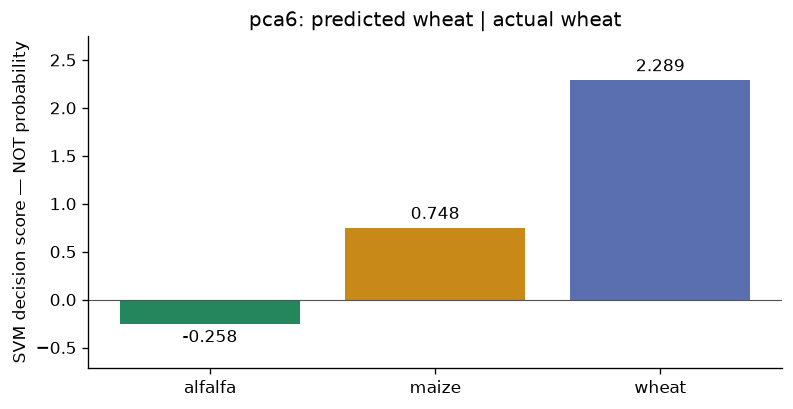

*How to read it:* Fresh decision scores for this actual field. They need not lie between zero and one or sum to one. SVC.predict supplies the crop prediction; these transformed one-vs-rest scores describe relative support, not calibrated confidence. No validation-set ranking or retuning is performed.

In [11]:
FIELD_INDEX = 0
DEMO_VIEW = 'pca6'

if not isinstance(FIELD_INDEX,int) or not 0<=FIELD_INDEX<len(validation):
    raise ValueError('FIELD_INDEX must be an integer from 0 to 149.')
if DEMO_VIEW not in VIEWS:raise ValueError('Choose pca4, pca6 or pca8.')
field=validation.iloc[FIELD_INDEX]
raw_field=field[features].to_numpy(dtype=float).reshape(1,-1)
pipeline=demo_models[DEMO_VIEW]
prepared=pipeline[:-1].transform(raw_field)[0]
predicted=pipeline.predict(raw_field)[0]
decision_scores=pipeline.decision_function(raw_field)[0]
np.testing.assert_array_equal(pipeline.classes_,LABELS)
display(Markdown(f'**Actual validation field `{field.sample_id}` · true crop: {field.target}**'))
display(pd.DataFrame({'feature':features,'actual measurement':field[features].to_numpy()}))
display(pd.DataFrame({'component':[f'PC{i+1}' for i in range(len(prepared))],'prepared value':prepared}))
comparison=pd.DataFrame([{'view':v,'prediction':demo_models[v].predict(raw_field)[0],
                          'actual crop':field.target,'correct':demo_models[v].predict(raw_field)[0]==field.target,
                          'origin':demo_provenance[v]} for v in VIEWS])
display(comparison)
print('Displayed model:',DEMO_VIEW,'| prediction:',predicted,'| correct:',predicted==field.target)
fig,ax=plt.subplots(figsize=(6.5,3.3),layout='constrained')
bars=ax.bar(LABELS,decision_scores,color=CROP_COLORS)
ax.bar_label(bars,labels=[f'{x:.3f}' for x in decision_scores],padding=3)
ax.axhline(0,color='#555555',linewidth=.7)
ax.margins(y=.18)
ax.set(ylabel='SVM decision score — NOT probability',title=f'{DEMO_VIEW}: predicted {predicted} | actual {field.target}')
show_figure(fig,f'04_field_{FIELD_INDEX}_{DEMO_VIEW}','Fresh decision scores for this actual field. They need not lie between zero and one or sum to one. SVC.predict supplies the crop prediction; these transformed one-vs-rest scores describe relative support, not calibrated confidence. No validation-set ranking or retuning is performed.')

## 7 — Brief recap of everything we have done

| Notebook one: ring QNN | Notebook two: PCA/SVM feature study |
|---|---|
| Four PCs → angle encoding → four-qubit ring circuit | Four/six/eight PCs → existing RBF SVM |
| Twelve trainable angles; two CX blocks; L-BFGS-B | Support vectors; training-only C/gamma selection |
| Seeds 0,1,2 varied initial quantum angles | Repeats 0,1,2 vary data partitions, split seeds 2026–2028 |
| Historical validation mean macro-F1 0.8943 | Training-only nested-CV mean F1 0.8939/0.9095/0.9106 |
| Three quantum output probabilities | SVC decision scores, not probabilities |

The evaluation sets and procedures differ: these numbers are **not a direct
quantum-versus-classical advantage comparison**. Full connectivity remains the
training-CV-selected quantum topology; ring remains the historical validation leader.

The feature study tested fixed logistic regression, fixed SVM and nested SVM,
plus controls (13 PCs, raw13, PCs5–8 alone and fold-selected four PCs). The added
components contained predictive clues, even with little variance. The later
six-qubit comparison did not exploit them successfully. More information in the
data does not guarantee that a particular quantum circuit can learn it.

We preserve the original scaling experiment, optimizer/depth experiments, all
topology models and both research notebooks. No hybrid, new quantum architecture,
test inference or validation-guided tuning is introduced here. Random training
folds are not geographic-transfer evidence, and overlapping repeats are not
independent samples. PCA/SVM gains concern this cohort and tested procedure.

**In VS Code:** open this `.ipynb`, select **Crop challenge** or `.venv/bin/python`,
then **Restart Kernel → Run All**. Leave `saved` first. Choose `quick` to learn
fitting or `full` to reproduce the nested-CV results. Change `FIELD_INDEX` and
`DEMO_VIEW` to explore another actual validation field. Each Run All creates a
new output folder; the first notebook and previous experiments remain unchanged.

In [12]:
changed=[p for p,h in locked.items() if digest(ROOT/p)!=h]
assert not changed,'Protected files changed: '+', '.join(changed)
audit={'status':'complete','study':'PCA/SVM feature representation','mode':RUN_MODE,'repeats':CV_REPEATS,
       'branch':branch,'python':sys.version.split()[0],'scikit_learn':version('scikit-learn'),
       'views':VIEWS,'learner':'existing svm_nested pipeline','scope':scope,
       'main_evaluation':'training-only OOF or quick training holdout',
       'full_reproduction_checks':reproduction_checks,'archived_OOF_files_rescored':len(saved_oof),
       'demo_fits':demo_config,'validation_demo':'fresh individual fields only; no aggregate validation ranking',
       'test_inference':False,'new_quantum_architecture':False,
       'previous_files_unchanged':True,'protected_sha256':locked}
(OUT/'session.json').write_text(json.dumps(audit,indent=2))
print('Complete: PCA/SVM notebook ran successfully. First notebook and previous files unchanged.')
print('New plots, metrics and provenance:',OUT)

Complete: PCA/SVM notebook ran successfully. First notebook and previous files unchanged.
New plots, metrics and provenance: /Users/alibourak/QiskitFallFest2026/QiskitFallFest_EMSI_QuantumAfrica/outputs/pca_svm_notebook/20261121T090342Z_057c1084
